# 02. Inventory simulation + analysis
This script demonstrates how to estimate inventory levels based on actual demand and lead time assumptions.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
import pandas as pd
import datetime as dt

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'

# Get data

In [93]:
# load single-store sales data
sales_long = pd.read_csv(
    data_dir / 'sales_long.csv',
    parse_dates=['date'],
    low_memory=False
)

# recall the level of this dataset
# i.e. a single store with many items over many dates
sales_long.groupby(['store_id','date','cat_id'])[['item_id']].nunique().head()

item_id
store_id date       cat_id            
CA_1     2011-01-29 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-01-30 FOODS         1437
                    HOBBIES        565

# Create demand summary
Note: We do not have actual inventory data which means we do not know if a zero-sales day is because of low demand or a stock outage.

In [3]:
# summarize historical demand by product
inventory_summary = (
    sales_long
    .groupby('item_id', observed=True)
    .agg(
        average_daily_demand=('units_sold', 'mean'),
        daily_demand_std=('units_sold', 'std'),
        total_units_sold=('units_sold', 'sum'),
        zero_demand_days=('units_sold', lambda x: (x == 0).sum()),
        days_observed=('units_sold', 'count')
    )
    .reset_index()
)

# calculate the percentage of days with zero demand
inventory_summary['zero_demand_pct'] = (
    inventory_summary['zero_demand_days']
    / inventory_summary['days_observed']
    * 100
)

# rank products by average daily demand
inventory_summary = inventory_summary.sort_values(
    'average_daily_demand',
    ascending=False
).reset_index(drop=True)

# inspect the results
print(f'Products: {inventory_summary["item_id"].nunique():,}')
print(f'Date range: {sales_long["date"].min().date()} to {sales_long["date"].max().date()}')

display(inventory_summary.round(2).head())

Products: 3,049
Date range: 2011-01-29 to 2016-04-24


,item_id,average_daily_demand,daily_demand_std,total_units_sold,zero_demand_days,days_observed,zero_demand_pct
0,FOODS_3_090,66.49,57.86,127203,469,1913,24.52
1,FOODS_3_586,45.84,16.40,87691,7,1913,0.37
2,FOODS_3_252,39.19,18.72,74971,6,1913,0.31
3,FOODS_3_120,32.36,33.54,61899,667,1913,34.87
4,FOODS_3_714,28.27,14.50,54080,7,1913,0.37


# Simulate inventory data

In [4]:








lead_time_days = 7 # <------------------ define initial inventory assumptions
target_service_level = 0.95
z_score = norm.ppf(target_service_level)










# calculate inventory policy by item
inventory_policy = inventory_summary.copy()

inventory_policy['daily_demand_std'] = (
    inventory_policy['daily_demand_std'].fillna(0)
)

# expected demand during supplier lead time
inventory_policy['lead_time_demand'] = (
    inventory_policy['average_daily_demand'] * lead_time_days
)

# safety stock for demand variability
inventory_policy['safety_stock'] = (
    z_score
    * inventory_policy['daily_demand_std']
    * np.sqrt(lead_time_days)
)

# reorder point = expected lead-time demand + safety stock
inventory_policy['reorder_point'] = np.ceil(
    inventory_policy['lead_time_demand']
    + inventory_policy['safety_stock']
).astype(int)

# round safety stock up to whole units
inventory_policy['safety_stock'] = np.ceil(
    inventory_policy['safety_stock']
).astype(int)

# inspect highest-demand items
inventory_policy = inventory_policy.sort_values(
    'average_daily_demand',
    ascending=False
).reset_index(drop=True)

display(
    inventory_policy[
        [
            'item_id',
            'average_daily_demand',
            'daily_demand_std',
            'lead_time_demand',
            'safety_stock',
            'reorder_point',
            'zero_demand_pct'
        ]
    ].round(2).head()
)

,item_id,average_daily_demand,daily_demand_std,lead_time_demand,safety_stock,reorder_point,zero_demand_pct
0,FOODS_3_090,66.49,57.86,465.46,252,718,24.52
1,FOODS_3_586,45.84,16.40,320.88,72,393,0.37
2,FOODS_3_252,39.19,18.72,274.33,82,356,0.31
3,FOODS_3_120,32.36,33.54,226.50,146,373,34.87
4,FOODS_3_714,28.27,14.50,197.89,64,262,0.37


# Explore results

In [28]:
ex_store_id = list(set(sales_long['store_id']))[0]
d1 = sales_long['date'].min().strftime("%Y-%m-%d")
d2 = sales_long['date'].max().strftime("%Y-%m-%d")
unique_n = sales_long['item_id'].nunique()

title_str = f"Store {ex_store_id} from {d1} to {d2} for {unique_n} unique items"

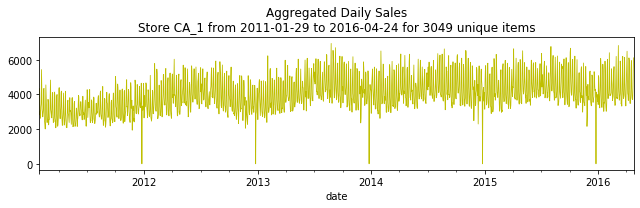

Observe the increasing trend with two flavors of seasonality:
One before each new year, and one during each mid-year.


In [92]:
# 1. daily sales, aggregated by date
daily = sales_long.groupby('date')['units_sold'].sum()
daily.plot(figsize=(9, 3), title=f'Aggregated Daily Sales\n{title_str}', linewidth=0.8, color = 'y')
plt.tight_layout()
plt.show()
print('Observe the increasing trend with two flavors of seasonality:\nOne before each new year, \
and one during each mid-year.')

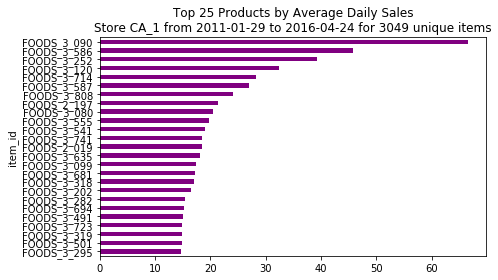

Interesting the top seven or so products dominate average sales.


In [42]:
# 2. top 10 products by average daily sales
N = 25
top = sales_long.groupby('item_id')['units_sold'].mean().nlargest(N).sort_values()
top.plot.barh(figsize=(7, 4), title=f'Top {N} Products by Average Daily Sales\n{title_str}', color = 'purple')
plt.tight_layout()
plt.show()

print('Interesting the top seven or so products dominate average sales.')

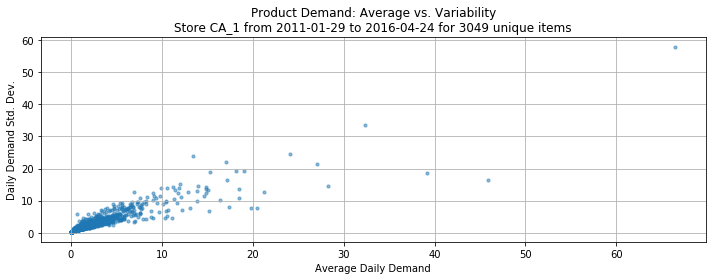

Observe that most products have low demand variability,
but items around X = 10 and beyond should be investigated;
we may need more safety stock to offset the high variability.


In [55]:
# 3. average demand vs. variability, using the existing summary
plt.figure(figsize=(10, 4))
plt.scatter(
    inventory_summary['average_daily_demand'],
    inventory_summary['daily_demand_std'],
    s=10, alpha=0.5
)
plt.title(f'Product Demand: Average vs. Variability\n{title_str}')
plt.xlabel('Average Daily Demand')
plt.ylabel('Daily Demand Std. Dev.')
plt.tight_layout()
plt.grid()
plt.show()

print('Observe that most products have low demand variability,\n\
but items around X = 10 and beyond should be investigated;\n\
we may need more safety stock to offset the high variability.')

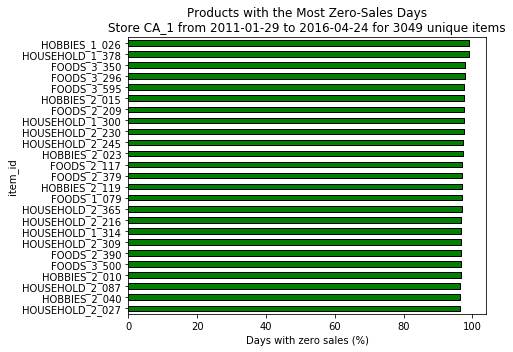

In [91]:
# 4. products with the most intermittent demand
intermittent = inventory_summary.nlargest(25, 'zero_demand_pct').sort_values('zero_demand_pct')
intermittent.plot.barh(
    x='item_id', y='zero_demand_pct', legend=False,
    figsize=(7, 5), title=f'Products with the Most Zero-Sales Days\n{title_str}',
    color = 'green', edgecolor='Black'
)
plt.xlabel('Days with zero sales (%)')
plt.tight_layout()
plt.show()


In [63]:
print('More than half of the products experience 68% or more days of zero-sales.\nTo truly understand this dynamic, \
we need actual inventory levels to confirm that we actually had stock for\nthe zero-sale days.')

inventory_summary['zero_demand_pct'].describe()

More than half of the products experience 68% or more days of zero-sales.
To truly understand this dynamic, we need actual inventory levels to confirm that we actually had stock for
the zero-sale days.


count    3049.000000
mean       63.947337
std        22.616034
min         0.313643
25%        48.039728
50%        68.531103
75%        82.645060
max        99.006796
Name: zero_demand_pct, dtype: float64

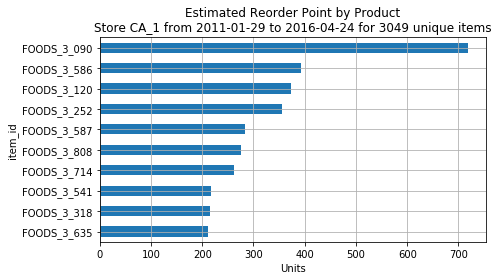

Observe the distinct groups of products beginning to form above, with FOODS_3_090 clearly dominating.
Next step is understanding why 090 is so different: Actual signal, or noise?


In [78]:
# 5. estimated reorder points for the top-demand products
#lead_time = 7 # define above
z = z_score  # approximately 95% service level; define above

policy = inventory_summary.copy()
policy['daily_demand_std'] = policy['daily_demand_std'].fillna(0)
policy['reorder_point'] = np.ceil(
    policy['average_daily_demand'] * lead_time
    + z * policy['daily_demand_std'] * np.sqrt(lead_time)
)

top_reorder = policy.nlargest(10, 'reorder_point').sort_values('reorder_point')
top_reorder.plot.barh(
    x='item_id', y='reorder_point', legend=False,
    figsize=(7, 4), title=f'Estimated Reorder Point by Product\n{title_str}',
    grid = True
)
plt.xlabel('Units')
plt.tight_layout()
plt.show()

print('Observe the distinct groups of products beginning to form above, with FOODS_3_090 clearly dominating.\n\
Next step is understanding why 090 is so different: Actual signal, or noise?')

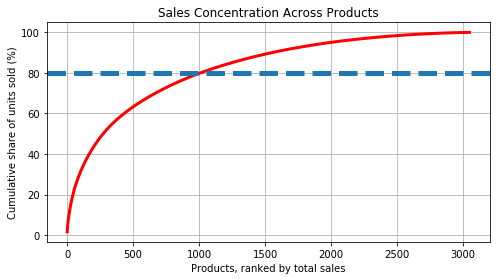

About 1/3 of this store's ~3000 items account for 80% of units sold.
Next step is to factor in revenue to understand if the remaining ~2000 items are pulling their weight.
Perhaps the remaining items are low sellers and can be cleaned out.


In [95]:
# 6. demand concentration: how much of total sales comes from top products?
sales_by_item = sales_long.groupby('item_id')['units_sold'].sum().sort_values(ascending=False)
cumulative_share = sales_by_item.cumsum() / sales_by_item.sum() * 100

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(cumulative_share) + 1), cumulative_share.values, lw = 3, color = 'red')
plt.axhline(80, linestyle='--', linewidth=5)
plt.xlabel('Products, ranked by total sales')
plt.ylabel('Cumulative share of units sold (%)')
plt.title('Sales Concentration Across Products')
plt.tight_layout()
plt.grid()
plt.show()

print("About 1/3 of this store\'s ~3000 items account for 80% of units sold.\
\nNext step is to factor in revenue to understand if the remaining ~2000 items are pulling their weight.\
\nPerhaps the remaining items are low sellers and can be cleaned out.")

In [6]:
print('done')

done
